# Contrastive Learning

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.dpi'] = 150

In [2]:
# Check available hardware
import torch
if torch.cuda.is_available():
    print(f'GPU is available, using GPU {torch.cuda.get_device_name(0)}')
    device = torch.device('cuda')
elif torch.mps.is_available():
    print(f'Apple Metal Performance Shaders framework is available, using {torch.device("mps")}')
    device = torch.device('mps')
else:
    print(f'Hardware acceleration not available, using CPU')
    device = torch.device('cpu')

GPU is available, using GPU Tesla T4


## Base Dataset: MNIST

In [3]:
import torch
import torchvision
from torchvision.transforms import v2
from torchvision.datasets import MNIST

transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=(0.5,), std=(0.5,))
])
mnist_train = MNIST(root='~/scr10/', train=True, transform=transform, download=True)
mnist_test = MNIST(root='~/scr10/', train=False, transform=transform, download=False)
print('Training dataset has length', len(mnist_train))
print('Testing dataset has length', len(mnist_test))

Training dataset has length 60000
Testing dataset has length 10000


In [4]:
x, y = mnist_train[0]
print('Input has shape', x.shape, 'and the output is', y)

Input has shape torch.Size([1, 28, 28]) and the output is 5


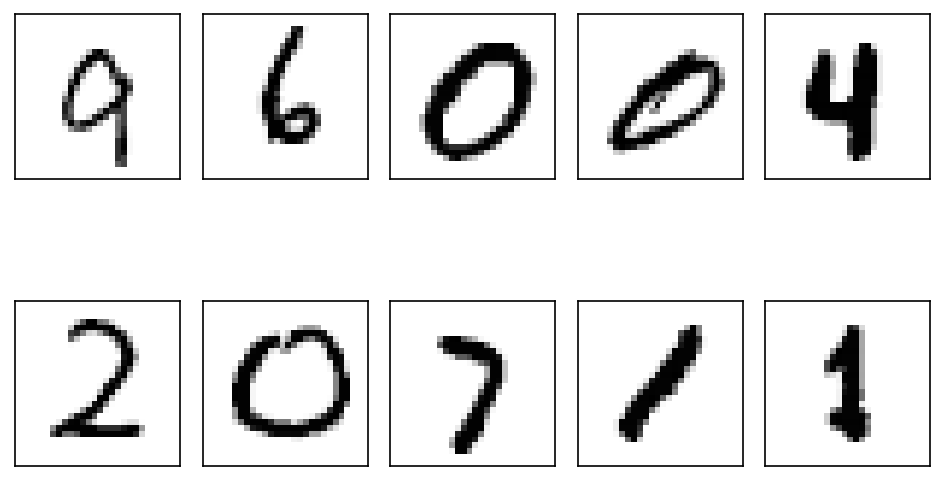

In [5]:
fig, ax = plt.subplots(2, 5, sharex=True, sharey=True)
ax = ax.flatten()
for ii in range(10):
    x, y = mnist_train[np.random.choice(len(mnist_train))]
    ax[ii].imshow(x.squeeze(), cmap='Greys')
    ax[ii].set(xticks=[], yticks=[])
plt.tight_layout()

In [6]:
mnist_train.targets

tensor([5, 0, 4,  ..., 5, 6, 8])

## Triplet learning

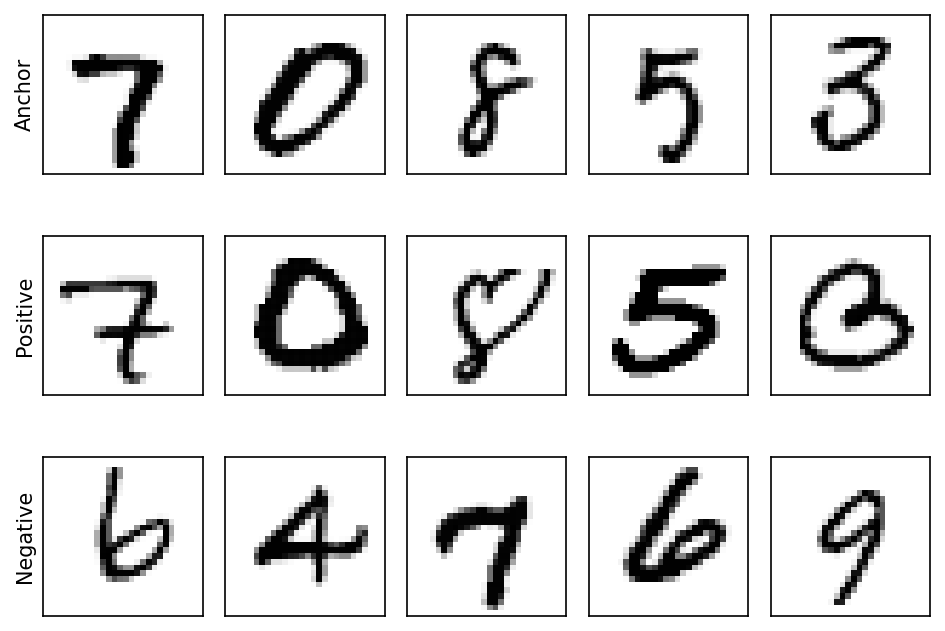

In [7]:
class TripletDataset(MNIST):
    def __getitem__(self, idx):
        anchor, y0 = super().__getitem__(idx)

        # Find index of another sample from this class
        pos_idxs = torch.argwhere(self.targets == y0)
        pos_idx = pos_idxs[np.random.choice(len(pos_idxs))].item()
        positive, _ = super().__getitem__(pos_idx)
        
        # Find index of another sample from a different class
        neg_idxs = torch.argwhere(self.targets != y0)
        neg_idx = neg_idxs[np.random.choice(len(neg_idxs))].item()
        negative, _ = super().__getitem__(neg_idx)

        return anchor, positive, negative

mnist_triplet = TripletDataset(root='~/scr10/', train=True, transform=transform, download=True)

fig, ax = plt.subplots(3, 5, sharex=True, sharey=True)
for ii in range(5):
    a, p, n = mnist_triplet[np.random.choice(len(mnist_triplet))]
    for axis, sample in zip(ax[:, ii], [a, p, n]):
        axis.imshow(sample.squeeze(), cmap='Greys')
        axis.set(xticks=[], yticks=[])

ax[0, 0].set_ylabel('Anchor')
ax[1, 0].set_ylabel('Positive')
ax[2, 0].set_ylabel('Negative')
plt.tight_layout()

In [20]:
import torch
import torch.nn as nn

class TripletLoss(nn.Module):
    def __init__(self, margin=1.0):
        super().__init__()
        self.margin = margin

    def forward(self, z_a, z_p, z_n):
        dist_ap = torch.linalg.norm(z_a - z_p, dim=1)
        dist_an = torch.linalg.norm(z_a - z_n, dim=1)

        zeros = torch.zeros_like(dist_ap)
        loss = torch.maximum(dist_ap - dist_an + self.margin, zeros)
        return loss.mean()

z_a = torch.randn(10, 4)
z_p = torch.randn(10, 4)
z_n = torch.randn(10, 4)

loss_fn = TripletLoss()
loss_fn(z_a, z_p, z_n)

tensor(0.9580)

In [21]:
from tqdm.notebook import tqdm, trange
from torch.utils.data import DataLoader
from sklearn.linear_model import LogisticRegression

import torch.nn as nn
import torch.nn.functional as F

def train_triplet(model, loss_fn, optimizer, train_dataset, val_dataset, 
                  batch_size=32, num_epochs=50, num_workers=2, device=device):
    # Send model to correct hardware device
    model = model.to(device)

    # Create dataloaders for train/validation
    train_loader = DataLoader(train_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)

    logging = {
        'train_loss': [],
        'val_acc': []
    }
    
    for epoch in range(num_epochs):
        # Prepare logging
        for key in logging:
            logging[key].append(0)

        model.train()
        for a, p, n, in tqdm(train_loader, leave=False):
            # Send x, y to GPU/TPU/etc.
            a = a.to(device)
            p = p.to(device)
            n = n.to(device)

            # Make a prediction on anchor, positive, negative samples
            z_a = model(a)
            z_p = model(p)
            z_n = model(n)

            # Compute the loss
            loss = loss_fn(z_a, z_p, z_n)

            # Backpropagate gradients, apply weight updates, reset gradients
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Logging
            logging['train_loss'][-1] += loss.item() * a.shape[0] / len(train_dataset)

        model.eval()
        with torch.no_grad():
            z_val = []
            y_val = []
            for x, y, in tqdm(val_loader, leave=False):
                # Send x, y to GPU/TPU/etc.
                x = x.to(device)
                z = model(x)

                z_val.append(z.cpu().numpy())
                y_val.append(y.numpy())

            z_val = np.concatenate(z_val)
            y_val = np.concatenate(y_val)

            classifier = LogisticRegression().fit(z_val, y_val)
            logging['val_acc'][-1] = classifier.score(z_val, y_val)

        outstr = f'Epoch {epoch+1} | '
        for key in logging.keys():
            outstr += f'{key} {logging[key][-1]:.3g} | '

        print(outstr)

    return model, logging
    
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28*28, 256),
    nn.ReLU(),
    nn.Dropout(p=0.2),
    nn.Linear(256, 5)
)
loss_fn = TripletLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model, logging = train_triplet(
    model, 
    loss_fn, 
    optimizer, 
    mnist_triplet, 
    mnist_test, 
    num_epochs=2,
    batch_size=128,
    num_workers=4,
)

  0%|          | 0/469 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 1 | train_loss 0.222 | val_acc 0.9 | 


  0%|          | 0/469 [00:00<?, ?it/s]

  0%|          | 0/79 [00:00<?, ?it/s]

Epoch 2 | train_loss 0.15 | val_acc 0.928 | 


### Inference

In [22]:
from sklearn.metrics import accuracy_score
# Inference
model.eval()
test_loader = DataLoader(mnist_test, batch_size=128, shuffle=False)

y_true = []
z_pred = []

with torch.no_grad():
    test_correct_ = 0.
    for xb, yb in tqdm(test_loader,leave=False):
        xb = xb.to(device)
        zb = model(xb)

        y_true.append(yb.cpu().numpy())
        z_pred.append(zb.cpu().numpy())

y_true = np.concatenate(y_true)
z_pred = np.concatenate(z_pred)

classifier = LogisticRegression().fit(z_pred, y_true)
y_pred = classifier.predict(z_pred)

print(y_pred.shape)

test_acc = accuracy_score(y_true, y_pred)
print(f"Test accuracy: {test_acc:.3f}")

  0%|          | 0/79 [00:00<?, ?it/s]

(10000,)
Test accuracy: 0.928


[Text(0.5, 0, 't-SNE 1'), Text(0, 0.5, 't-SNE 2')]

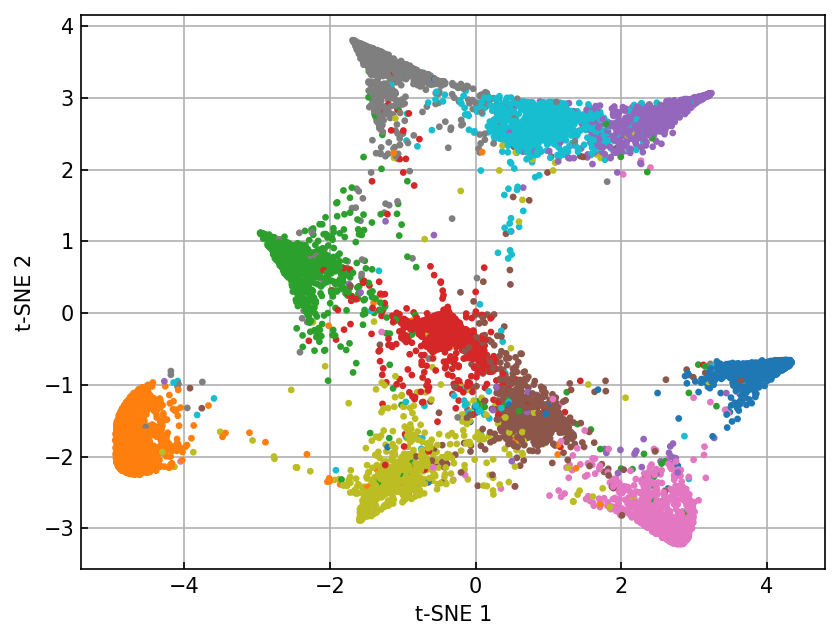

In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

scaler = StandardScaler()
viz = TSNE(n_components=2, n_iter=250)
z_2d = viz.fit_transform(scaler.fit_transform(z_pred))

fig, ax = plt.subplots()
ax.scatter(
    z_2d[:, 0],
    z_2d[:, 1],
    c=y_true,
    cmap='tab10',
    s=5
)
ax.set(xlabel='t-SNE 1', ylabel='t-SNE 2')

## SimCLR

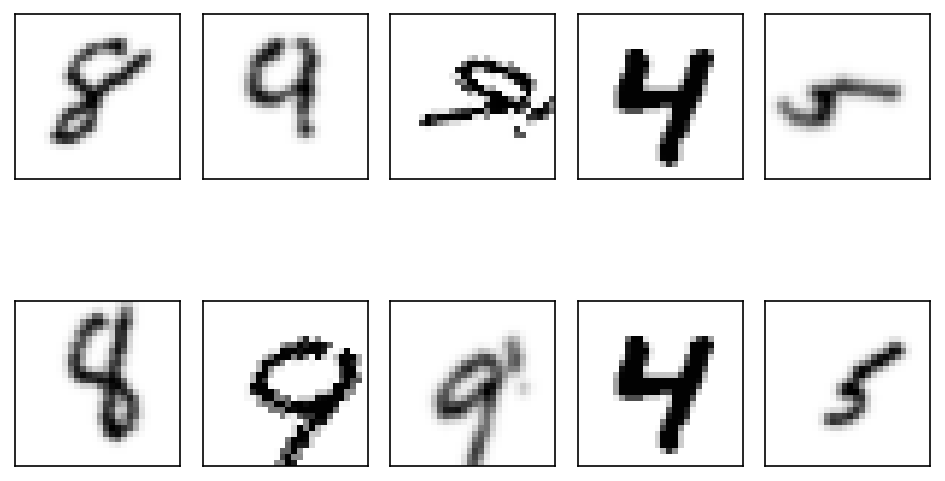

In [46]:
from torch.utils.data import random_split, Dataset

class PairDataset(Dataset):
    def __init__(self, base_dataset, labeled=False):
        super().__init__()
        self.base_dataset = base_dataset
        self.labeled = labeled

    def __len__(self):
        return len(self.base_dataset)
        
    def __getitem__(self, idx):
        x1, y = self.base_dataset[idx]
        x2, y = self.base_dataset[idx]

        if self.labeled:
            return x1, x2, y

        else:
            return x1, x2

augmentation_transform = v2.Compose([
    v2.ToImage(),
    v2.RandomApply([
        v2.RandomAffine(degrees=[-45, 45], translate=[0.1, 0.1], scale=[0.8, 1.2]),
        v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.2),
        v2.GaussianBlur(kernel_size=7, sigma=(0.05, 1)),
    ]),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=(0.5,), std=(0.5,))
])

mnist_base = MNIST(root='~/scr10/', train=True, transform=augmentation_transform, download=True)
mnist_train, mnist_val = random_split(mnist_base, [0.8, 0.2])

mnist_pair_train = PairDataset(mnist_train)
mnist_pair_val = PairDataset(mnist_val, labeled=True)

fig, ax = plt.subplots(2, 5, sharex=True, sharey=True)
for ii in range(5):
    x0, x1 = mnist_pair_train[np.random.choice(len(mnist_pair_train))]
    for axis, sample in zip(ax[:, ii], [x0, x1]):
        axis.imshow(sample.squeeze(), cmap='Greys')
        axis.set(xticks=[], yticks=[])

plt.tight_layout()

In [47]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision.models import resnet18

class SimCLRModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = resnet18()
        self.encoder.conv1 = nn.Conv2d(1, 64, kernel_size=7, bias=False) # Correct to 1-channel input
        self.encoder.fc = nn.Linear(512, 10)

        self.projection = nn.Sequential(
            nn.Linear(10, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        h = self.encoder(x)
        z = self.projection(h)
        return h, z

model = SimCLRModel().to(device)
h, z = model(x[None].to(device))
print(h.shape, z.shape)

torch.Size([1, 10]) torch.Size([1, 10])


In [48]:
import torch
import torch.nn as nn

neg_inf = np.log(np.finfo(np.float32).eps)

def NTXentLoss(z1, z2, labels=None, temperature=1.0):
    B, E = z1.shape

    # Normalize to unit vectors
    z1 = F.normalize(z1, dim=-1)
    z2 = F.normalize(z2, dim=-1)

    # Cosine similarity between batch elements, size (B, B)
    logits = z1 @ z2.T / temperature 
    targets = torch.eye(B, device=z1.device, dtype=z1.dtype)

    if labels is not None:
        # Check whether any positive pairs are "off-diagonal"
        # i.e., do we have the same entry within the batch
        if len(labels.shape) == 1:
            labels = labels[:, None]
        
        positive_mask = torch.eq(labels, labels.T)
        diagonal_mask = targets.bool()

        off_diagonal_positives = torch.logical_and(positive_mask, torch.logical_not(diagonal_mask))

        # Softmax -> 0 if unnormalized logit -> negative infinity
        logits[off_diagonal_positives] += neg_inf # Smallest positive number s.t. log(n) is a float

    loss_12 = F.cross_entropy(logits, targets)
    loss_21 = F.cross_entropy(logits.T, targets)
    return 0.5 * (loss_12 + loss_21)

z1 = torch.randn(10, 4)
z2 = torch.randn(10, 4)

loss_fn = NTXentLoss
loss_fn(z1, z2)

tensor(2.5744)

In [57]:
from tqdm.notebook import tqdm, trange
from torch.utils.data import DataLoader
from sklearn.linear_model import LogisticRegression

import torch.nn as nn
import torch.nn.functional as F

def train_simclr(model, loss_fn, optimizer, train_dataset, val_dataset, 
                 batch_size=32, num_epochs=50, num_workers=2, device=device):
    # Send model to correct hardware device
    model = model.to(device)

    # Create dataloaders for train/validation
    train_loader = DataLoader(train_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, num_workers=num_workers, shuffle=False)

    logging = {
        'train_loss': [],
        'val_loss': [],
        'val_acc': []
    }
    
    for epoch in range(num_epochs):
        # Prepare logging
        for key in logging:
            logging[key].append(0)

        model.train()
        for x1, x2 in tqdm(train_loader, leave=False):
            # Send x, y to GPU/TPU/etc.
            x1 = x1.to(device)
            x2 = x2.to(device)

            # Make a prediction on all samples
            h1, z1 = model(x1)
            h2, z2 = model(x2)

            # Compute the loss
            loss = loss_fn(z1, z2)

            # Backpropagate gradients, apply weight updates, reset gradients
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Logging
            logging['train_loss'][-1] += loss.item() * x1.shape[0] / len(train_dataset)
        
        model.eval()
        with torch.no_grad():
            h_val = []
            y_val = []
            for x1, x2, y in tqdm(val_loader, leave=False):
                # Send x, y to GPU/TPU/etc.
                x1 = x1.to(device)
                x2 = x2.to(device)
                y  = y.to(device)
    
                # Make a prediction on all samples
                h1, z1 = model(x1)
                h2, z2 = model(x2)
    
                # Compute the loss
                loss = loss_fn(z1, z2, y)

                # Logging
                logging['val_loss'][-1] += loss.item() * x1.shape[0] / len(val_dataset)

                h_val.append(h1.cpu().numpy())
                y_val.append(y.cpu().numpy())

            h_val = np.concatenate(h_val)
            y_val = np.concatenate(y_val)

            classifier = LogisticRegression().fit(h_val, y_val)
            logging['val_acc'][-1] = classifier.score(h_val, y_val)

        outstr = f'Epoch {epoch+1} | '
        for key in logging.keys():
            outstr += f'{key} {logging[key][-1]:.3g} | '

        print(outstr)

    return model, logging

torch.manual_seed(42)
model = SimCLRModel()
loss_fn = NTXentLoss
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)
model, logging = train_simclr(
    model, 
    loss_fn, 
    optimizer, 
    mnist_pair_train, 
    mnist_pair_val, 
    num_epochs=5,
    batch_size=128,
    num_workers=4,
)

  0%|          | 0/375 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

Epoch 1 | train_loss 4.07 | val_loss 3.81 | val_acc 0.799 | 


/opt/conda/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  0%|          | 0/375 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

... (10 outputs left out)

  0%|          | 0/375 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

Epoch 5 | train_loss 3.93 | val_loss 3.73 | val_acc 0.94 | 


/opt/conda/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Inference

In [58]:
from sklearn.metrics import accuracy_score
# Inference
model.eval()
test_loader = DataLoader(mnist_test, batch_size=128, shuffle=False)

y_true = []
h_pred = []

with torch.no_grad():
    test_correct_ = 0.
    for xb, yb in tqdm(test_loader,leave=False):
        xb = xb.to(device)
        hb, zb = model(xb)

        y_true.append(yb.cpu().numpy())
        h_pred.append(hb.cpu().numpy())

y_true = np.concatenate(y_true)
h_pred = np.concatenate(h_pred)

classifier = LogisticRegression().fit(h_pred, y_true)
y_pred = classifier.predict(h_pred)

print(y_pred.shape)

test_acc = accuracy_score(y_true, y_pred)
print(f"Test accuracy: {test_acc:.3f}")

  0%|          | 0/79 [00:00<?, ?it/s]

(10000,)
Test accuracy: 0.953


/opt/conda/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


[Text(0.5, 0, 't-SNE 1'), Text(0, 0.5, 't-SNE 2')]

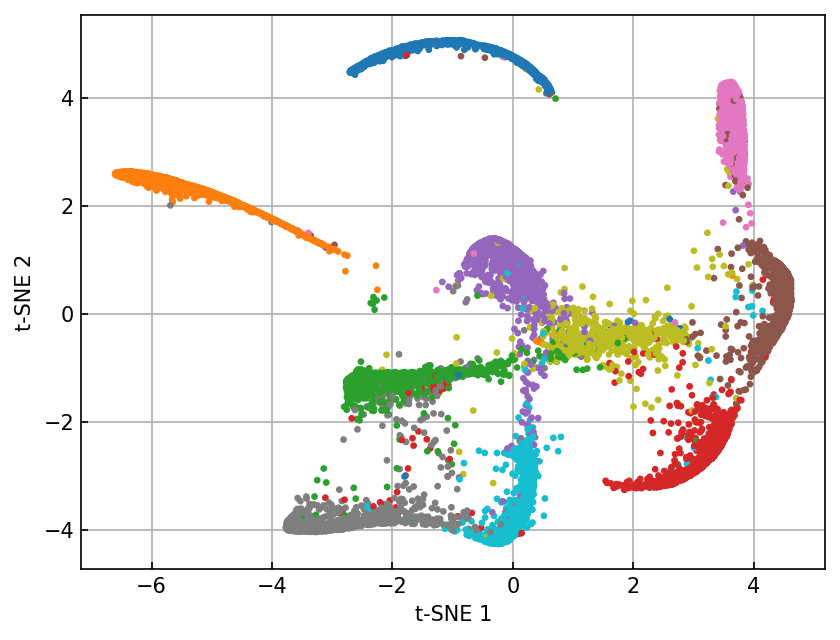

In [59]:
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

scaler = StandardScaler()
viz = TSNE(n_components=2, n_iter=250)
h_2d = viz.fit_transform(scaler.fit_transform(h_pred))

fig, ax = plt.subplots()
ax.scatter(
    h_2d[:, 0],
    h_2d[:, 1],
    c=y_true,
    cmap='tab10',
    s=5
)
ax.set(xlabel='t-SNE 1', ylabel='t-SNE 2')